In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Define processed data directory
DATA_DIR = Path("../data/processed")

# Load processed datasets
daily_activity = pd.read_csv(DATA_DIR / "daily_activity_clean.csv")
minute_sleep = pd.read_csv(DATA_DIR / "minute_sleep_clean.csv")
weight = pd.read_csv(DATA_DIR / "weight_clean.csv")
hourly_activity = pd.read_csv(DATA_DIR / "hourly_activity_clean.csv")
minute_activity = pd.read_csv(DATA_DIR / "minute_activity_clean.csv")
heartrate = pd.read_csv(DATA_DIR / "heartrate_seconds_clean.csv")

# Section A : Participant-level profiling

In [2]:
## Participant-Level Behavioural Profiling

In [3]:
# Create total active minutes
daily_activity['total_active_minutes'] = (
    daily_activity['very_active_minutes'] +
    daily_activity['fairly_active_minutes'] +
    daily_activity['lightly_active_minutes']
)

# Aggregate daily observations at participant level
participant_summary = daily_activity.groupby('id').agg(

    # Observation coverage
    recorded_days=('activity_date', 'count'),
    complete_days=('is_complete_day', 'sum'),

    # Step statistics
    avg_steps=('total_steps', 'mean'),
    median_steps=('total_steps', 'median'),
    std_steps=('total_steps', 'std'),

    # Calorie statistics
    avg_calories=('calories', 'mean'),
    std_calories=('calories', 'std'),

    # Activity behaviour
    avg_sedentary_minutes=('sedentary_minutes', 'mean'),
    avg_active_minutes=('total_active_minutes', 'mean'),

    # Distance
    avg_total_distance=('total_distance', 'mean')

).reset_index()

# Calculate complete-day percentage
participant_summary['complete_day_percentage'] = (
    participant_summary['complete_days'] /
    participant_summary['recorded_days']
) * 100

# Display participant summary
participant_summary = participant_summary.sort_values(
    by='avg_steps',
    ascending=False
)

display(participant_summary.round(2))

,id,recorded_days,complete_days,avg_steps,median_steps,std_steps,avg_calories,std_calories,avg_sedentary_minutes,avg_active_minutes,avg_total_distance,complete_day_percentage
34,8877689391,12,11,17417.08,17585.0,7871.54,3451.17,970.88,1046.17,322.92,14.09,91.67
29,8053475328,11,10,14844.36,16435.0,6519.27,2893.18,757.24,1114.45,250.55,11.58,90.91
26,6962181067,14,0,12639.71,12458.5,2921.02,2089.21,352.05,606.29,322.93,8.65,0.00
27,7007744171,12,7,12260.33,12126.0,2494.48,2627.08,527.64,1000.67,338.42,8.86,58.33
5,2022484408,12,11,12174.92,12083.5,3851.22,2475.33,484.53,1058.92,316.42,8.77,91.67
0,1503960366,19,4,11640.53,12041.0,3329.63,1796.21,435.10,809.84,279.89,7.61,21.05
8,2347167796,15,0,9800.07,10209.0,3660.71,2021.33,478.68,683.87,288.47,6.51,0.00
2,1644430081,10,9,9274.80,8983.5,5658.12,2916.40,945.34,1034.20,286.00,6.75,90.00
12,3977333714,12,0,8663.92,9324.0,4796.25,1398.08,425.47,708.75,250.33,5.81,0.00
21,5577150313,11,0,8608.18,9776.0,3534.59,3300.27,784.35,665.82,267.27,6.45,0.00


Finding 1 — Large differences in average daily steps
- The highest average daily step count is approximately 17,417, belonging to participant 8877689391.
- The lowest is 0, belonging to participant 4388161847.
- This indicates considerable differences in recorded physical activity across participants.
- However, remember that these are recorded averages, not necessarily equally reliable estimates of actual daily behaviour.

Finding 2 — High step variability among some participants
For example:
- Participant 8877689391: SD = 7,871.54.
- Participant 8053475328: SD = 6,519.27.
- Participant 1644430081: SD = 5,658.12.
These participants demonstrate considerable day-to-day variation in recorded steps.

We will investigate whether incomplete observations contribute to this variation.

Finding 3 — Average steps and median steps can differ considerably
Consider participant 8253242879:
- Average steps = 2,389.92.
- Median steps = 818.
The difference suggests that some higher step-count observations may be influencing the mean.

Similarly, participant 1624580081 has an average of 4,226.26 but a median of 1,985.

This is why calculating both statistics is useful.

Finding 4 — Completeness and activity are not interchangeable
Participant 6962181067 has:
- Average steps = 12,639.71.
- Complete days = 0.
- Recorded days = 14.
This is an especially important observation.

The participant appears highly active based on recorded step counts, but none of the observations satisfy our complete-day criterion.

We cannot confidently compare this average with participants having mostly complete days.

Finding 5 — An observation requiring further investigation
Participant 4388161847 has:
- Average steps = 0.
- Average distance = 0.
- Average active minutes = 0.
- Average sedentary minutes = 1,384.25.
- Complete-day percentage = 87.5%.

 This is an interesting pattern: the participant has predominantly complete days but no recorded steps or distance.

##### **Conclusion:**
Participant-level behavioural profiling revealed substantial heterogeneity in recorded physical activity across the 35 participants. Average daily steps varied from 0 to approximately 17,417, indicating considerable differences in recorded activity levels. Differences between mean and median step counts suggest that some participants exhibit asymmetric activity distributions. Additionally, observation completeness varies considerably, making it important to account for data coverage when comparing participants. Certain unusual activity profiles, including participants with zero recorded steps despite high daily completeness, warrant further investigation.

In [4]:
## Participant Coverage Analysis

In [5]:
# Select participant coverage variables
coverage_summary = participant_summary[
    ['id', 'recorded_days', 'complete_days',
     'complete_day_percentage']
].copy()

# Participants with highest observation coverage
print("Top 5 participants by recorded days:")

display(
    coverage_summary.nlargest(5, 'recorded_days')
)

# Participants with lowest observation coverage
print("\nBottom 5 participants by recorded days:")

display(
    coverage_summary.nsmallest(5, 'recorded_days')
)

# Participants with lowest complete-day percentage
print("\nBottom 5 participants by complete-day percentage:")

display(
    coverage_summary.nsmallest(5, 'complete_day_percentage')
)

Top 5 participants by recorded days:


,id,recorded_days,complete_days,complete_day_percentage
13,4020332650,32,16,50.000000
14,4057192912,32,31,96.875000
0,1503960366,19,4,21.052632
1,1624580081,19,18,94.736842
8,2347167796,15,0,0.000000



Bottom 5 participants by recorded days:


,id,recorded_days,complete_days,complete_day_percentage
32,8583815059,8,7,87.500000
10,2891001357,8,7,87.500000
16,4388161847,8,7,87.500000
25,6775888955,9,4,44.444444
24,6391747486,9,8,88.888889



Bottom 5 participants by complete-day percentage:


,id,recorded_days,complete_days,complete_day_percentage
26,6962181067,14,0,0.0
8,2347167796,15,0,0.0
12,3977333714,12,0,0.0
21,5577150313,11,0,0.0
20,5553957443,12,0,0.0


Finding 1 — Unequal observation coverage
The number of recorded days varies from 8 to 32 days.
- Highest coverage: Participants 4020332650 and 4057192912, with 32 days each.
- Lowest coverage: Participants 8583815059, 2891001357 and 4388161847, with 8 days each.
This indicates unequal observation coverage.

Finding 2 — Recorded days do not guarantee complete days   
- Participants with identical recorded-day counts can have very different completeness.    
- Five participants have zero complete days    

Therefore, observation count alone cannot represent data quality.

Finding 3 — Some participants have low coverage but high completeness
For example, participants 8583815059, 2891001357 and 4388161847 each have 8 recorded days, of which 7 are complete.

Their completeness percentage is 87.5%.

This demonstrates that observation coverage and observation completeness are two separate dimension

#### **Conclusion:**
Participant-wise coverage analysis revealed substantial variation in observation availability, with recorded days ranging from 8 to 32 per participant. Furthermore, the proportion of complete days varied considerably. Five participants had no complete-day observations despite having 11–15 recorded days. The findings demonstrate that observation coverage and data completeness must be considered separately when comparing participant-level physical activity patterns.

In [7]:
## Participant-Level Activity Variability

In [8]:
# Select relevant participant-level variables

variability_summary = participant_summary[
    ['id', 'recorded_days', 'complete_day_percentage',
     'avg_steps', 'std_steps']
].copy()

# Five participants with highest step variability
print("Highest step variability:")

display(
    variability_summary.nlargest(5, 'std_steps')
)

# Five participants with lowest step variability
print("\nLowest step variability:")

display(
    variability_summary.nsmallest(5, 'std_steps')
)

Highest step variability:


,id,recorded_days,complete_day_percentage,avg_steps,std_steps
34,8877689391,12,91.666667,17417.083333,7871.543876
29,8053475328,11,90.909091,14844.363636,6519.272724
22,6117666160,10,40.000000,8248.600000,5826.192204
2,1644430081,10,90.000000,9274.800000,5658.118431
25,6775888955,9,44.444444,5559.000000,5231.217831



Lowest step variability:


,id,recorded_days,complete_day_percentage,avg_steps,std_steps
16,4388161847,8,87.500000,0.000000,0.000000
11,3372868164,10,90.000000,6127.500000,1440.521453
10,2891001357,8,87.500000,773.625000,1534.921118
4,1927972279,12,16.666667,2180.833333,1625.793951
32,8583815059,8,87.500000,3045.500000,1665.128910


Interpretation: Highest step variability
- Participant 8877689391 has the highest variability, with a standard deviation of approximately 7,872 steps.
- Participant 8053475328 also exhibits substantial variation.
- Participants 6117666160 and 6775888955 have relatively low complete-day percentages, which could influence their variability estimates.
- Participants 8877689391 and 1644430081 have high completeness, suggesting that their observed variability cannot simply be attributed to incomplete days.

Interpretation: Lowest step variability
- Participant 4388161847 has zero standard deviation because all recorded step counts are zero.
- Participant 3372868164 has relatively consistent recorded step counts.
- Participant 2891001357 has low average steps but relatively low variability.
- Participant 1927972279 has low completeness, so its variability should be interpreted cautiously.
An important distinction: low variability does not necessarily mean healthy or desirable behaviour. It simply indicates consistency in recorded step counts.

#### **Conclusion:**
Participant-level variability analysis revealed substantial differences in daily step-count consistency. Participant 8877689391 exhibited the highest standard deviation (7,871.54 steps), followed by participant 8053475328 (6,519.27 steps). Conversely, participant 4388161847 had zero variability because all recorded step counts were zero. The analysis also highlighted that incomplete daily observations may influence variability estimates for certain participants. Therefore, behavioural variability should be interpreted alongside observation completeness and average activity levels.

In [9]:
## Complete-Day vs All-Day Activity Comparison

In [10]:
# Filter only complete-day observations

complete_df = daily_activity[
    daily_activity['is_complete_day'] == True
]

# Calculate participant-level statistics using complete days

complete_day_summary = complete_df.groupby('id').agg(

    complete_day_count=('total_steps', 'count'),

    avg_steps_complete=('total_steps', 'mean'),

    median_steps_complete=('total_steps', 'median'),

    std_steps_complete=('total_steps', 'std')

).reset_index()

# Display results

display(complete_day_summary.round(2))

,id,complete_day_count,avg_steps_complete,median_steps_complete,std_steps_complete
0,1503960366,4,11415.75,11472.0,1035.19
1,1624580081,18,4092.89,1945.0,4502.25
2,1644430081,9,10157.67,9921.0,5219.89
3,1844505072,7,4187.29,5367.0,2913.87
4,1927972279,2,643.50,643.5,176.07
5,2022484408,11,12671.09,13023.0,3614.60
6,2320127002,11,3233.00,2277.0,3582.67
7,2873212765,11,6558.36,7350.0,4194.92
8,2891001357,7,589.43,0.0,1559.48
9,3372868164,9,6290.33,5861.0,1426.95


Interpretation:

The complete-day averages are not consistently higher than the all-day averages.

Some increase, while others decrease.

This is important because incomplete observations do not necessarily cause a downward shift in every participant's average. The direction depends on the recorded observations.

Finding 1 — Some participants have very few complete observations
For example:
- Participant 4319703577: only 1 complete day.
- Participant 4702921684: only 1 complete day.
- Participant 7086361926: only 2 complete days.
- Participant 1927972279: only 2 complete days.   
An average based on one or two days is not a reliable representation of longer-term behavioural patterns.

Finding 2 — Some complete-day averages are still zero
Participant 4388161847 has seven complete days, and all seven have zero recorded steps.

This confirms that complete-day status does not necessarily imply non-zero physical activity.

Zero-step observations should remain valid unless further investigation establishes otherwise.

#### **Conclusion**:
A comparison of participant-level step averages using all recorded days and complete days revealed differences in both the magnitude and direction of the estimates. For example, participant 6775888955 showed a reduction from 5,559 to 3,764 average steps, whereas participant 8053475328 showed an increase from 14,844 to 16,300 steps. Furthermore, several participants had very few complete-day observations, limiting the reliability of their complete-day averages. These findings demonstrate the importance of considering daily completeness when interpreting participant-level activity patterns.

In [11]:
## Compare All-Day and Complete-Day Averages

In [12]:
# Select original participant-level averages
all_day_summary = participant_summary[
    ['id', 'recorded_days', 'complete_days', 'avg_steps']
].copy()

# Merge complete-day averages
comparison = all_day_summary.merge(
    complete_day_summary,
    on='id',
    how='left'
)

# Calculate absolute difference
comparison['step_average_difference'] = (
    comparison['avg_steps_complete'] -
    comparison['avg_steps']
)

# Calculate percentage difference
comparison['step_average_difference_pct'] = (
    comparison['step_average_difference'] /
    comparison['avg_steps'].replace(0, np.nan)
) * 100

# Display comparison
display(comparison.round(2))

,id,recorded_days,complete_days,avg_steps,complete_day_count,avg_steps_complete,median_steps_complete,std_steps_complete,step_average_difference,step_average_difference_pct
0,8877689391,12,11,17417.08,11.0,18786.82,18700.0,6587.25,1369.73,7.86
1,8053475328,11,10,14844.36,10.0,16299.80,16756.5,4618.76,1455.44,9.80
2,6962181067,14,0,12639.71,NaN,NaN,NaN,NaN,NaN,NaN
3,7007744171,12,7,12260.33,7.0,12249.29,12168.0,1789.83,-11.05,-0.09
4,2022484408,12,11,12174.92,11.0,12671.09,13023.0,3614.60,496.17,4.08
5,1503960366,19,4,11640.53,4.0,11415.75,11472.0,1035.19,-224.78,-1.93
6,2347167796,15,0,9800.07,NaN,NaN,NaN,NaN,NaN,NaN
7,1644430081,10,9,9274.80,9.0,10157.67,9921.0,5219.89,882.87,9.52
8,3977333714,12,0,8663.92,NaN,NaN,NaN,NaN,NaN,NaN
9,5577150313,11,0,8608.18,NaN,NaN,NaN,NaN,NaN,NaN


Interpretation:
- Some participants have higher average steps after filtering.
- Others have lower average steps.
- The magnitude of the difference varies substantially.
This tells us that incomplete-day filtering does not systematically increase average steps for every participant.

Finding 2 — Some participants show substantial changes
Examples:
- Participant 1927972279: decrease of 70.49%.
- Participant 6117666160: decrease of 47.19%.
- Participant 8792009665: increase of 42.55%.
- Participant 6775888955: decrease of 32.29%.
These differences deserve attention, particularly when interpreting participant-level behavioural profiles.

Finding 3 — Seven participants have no complete-day estimates
Their complete-day averages are NaN because they have zero complete-day observations.

We must retain these participants in the overall dataset, but complete-day comparisons cannot be performed for them.

Finding 4 — The number of complete observations matters
Consider participant 4319703577.

They have only one complete-day observation, with zero steps.

Their complete-day average is therefore zero, but this does not establish that their usual activity level is zero.

A one-day estimate should not be treated as a reliable participant-level behavioural profile.

Similarly, averages based on two or three complete days should be interpreted cautiously.

#### **Conclusion:**
Comparing participant-level step averages using all recorded days and complete days revealed substantial differences in both the magnitude and direction of estimates. Some participants experienced considerable increases, while others showed reductions after filtering incomplete observations. Seven participants had no complete-day observations, making complete-day comparisons unavailable for them. The findings demonstrate that data completeness can influence participant-level activity estimates, but restricting analysis to complete days does not consistently increase average step counts. The number of available complete observations must also be considered when interpreting these estimates.

In [14]:
## Quantify the impact of complete-day filtering

In [15]:
# Separate participants with available complete-day averages
valid_comparison = comparison.dropna(
    subset=['avg_steps_complete']
).copy()

# Count the direction of change
increased = (
    valid_comparison['step_average_difference'] > 0
).sum()

decreased = (
    valid_comparison['step_average_difference'] < 0
).sum()

unchanged = (
    valid_comparison['step_average_difference'] == 0
).sum()

unavailable = comparison['avg_steps_complete'].isna().sum()

print("Participants with increased average steps:", increased)
print("Participants with decreased average steps:", decreased)
print("Participants with unchanged average steps:", unchanged)
print("Participants without complete-day averages:", unavailable)

# Largest increases
print("\nLargest increases:")
display(
    valid_comparison.nlargest(
        5, 'step_average_difference'
    )[
        ['id', 'complete_day_count', 'avg_steps',
         'avg_steps_complete', 'step_average_difference']
    ]
)

# Largest decreases
print("\nLargest decreases:")
display(
    valid_comparison.nsmallest(
        5, 'step_average_difference'
    )[
        ['id', 'complete_day_count', 'avg_steps',
         'avg_steps_complete', 'step_average_difference']
    ]
)

Participants with increased average steps: 15
Participants with decreased average steps: 12
Participants with unchanged average steps: 1
Participants without complete-day averages: 7

Largest increases:


,id,complete_day_count,avg_steps,avg_steps_complete,step_average_difference
1,8053475328,10.0,14844.363636,16299.800000,1455.436364
0,8877689391,11.0,17417.083333,18786.818182,1369.734848
26,8792009665,3.0,3094.916667,4411.666667,1316.750000
7,1644430081,9.0,9274.800000,10157.666667,882.866667
18,4558609924,9.0,5785.250000,6533.777778,748.527778



Largest decreases:


,id,complete_day_count,avg_steps,avg_steps_complete,step_average_difference
13,4702921684,1.0,7943.400000,0.00,-7943.400000
14,4319703577,1.0,7820.583333,0.00,-7820.583333
11,6117666160,4.0,8248.600000,4355.75,-3892.850000
17,7086361926,2.0,6103.916667,4025.00,-2078.916667
20,6775888955,4.0,5559.000000,3764.00,-1795.000000


The comparison demonstrates that complete-day filtering changes participant-level step averages, but the direction and magnitude of the change vary across participants.

This is a sensitivity analysis, not evidence that incomplete days necessarily inflate or reduce activity estimates. The number of complete days also matters: an average calculated from one or two days may not represent a participant's usual behaviour.

For subsequent EDA, we should therefore retain the distinction between:
- All recorded days, which provide broader coverage.
- Complete days, which provide more consistent daily observation coverage.

#### Section A — Report-ready conclusion
Participant-level profiling revealed substantial differences in activity levels, observation coverage, and day-to-day variability. Participants had an average of 13.06 recorded days, but only 6.66 complete days on average. The mean participant-level average step count was 6,538 steps per day, with considerable variation between participants.

The comparison of all recorded days against complete days showed that filtering incomplete days did not produce a uniform change in average steps. Among participants with complete-day data, 15 had higher averages, 12 had lower averages, and one remained unchanged. Seven participants had no complete-day observations.

These findings highlight the importance of considering both participant coverage and daily completeness when interpreting activity patterns. Participant-level averages should not be interpreted without considering the number of observations supporting them.

# Section B — Daily Activity Analysis:

In [16]:
# Descriptive statistics of daily step counts

step_summary = daily_activity['total_steps'].describe()

print("Descriptive Statistics:")
display(step_summary.to_frame(name='Daily Steps').round(2))

print("\nAdditional Statistics:")

print(
    "Median:",
    daily_activity['total_steps'].median()
)

print(
    "Skewness:",
    daily_activity['total_steps'].skew().round(3)
)

print(
    "Zero-step records:",
    (daily_activity['total_steps'] == 0).sum()
)

print(
    "Negative-step records:",
    (daily_activity['total_steps'] < 0).sum()
)

Descriptive Statistics:


,Daily Steps
count,457.00
mean,6546.56
std,5398.49
min,0.00
25%,1988.00
50%,5986.00
75%,10198.00
max,28497.00



Additional Statistics:
Median: 5986.0
Skewness: 0.803
Zero-step records: 61
Negative-step records: 0


Across 457 recorded participant-days, the mean daily step count was 6,546.56, while the median was 5,986. The standard deviation of 5,398.49 indicates substantial variability in daily activity. The distribution was positively skewed (skewness = 0.803), suggesting that a smaller number of highly active days increased the mean relative to the median. Additionally, 61 observations (13.35%) recorded zero steps. These observations are retained because zero steps do not necessarily indicate missing data.

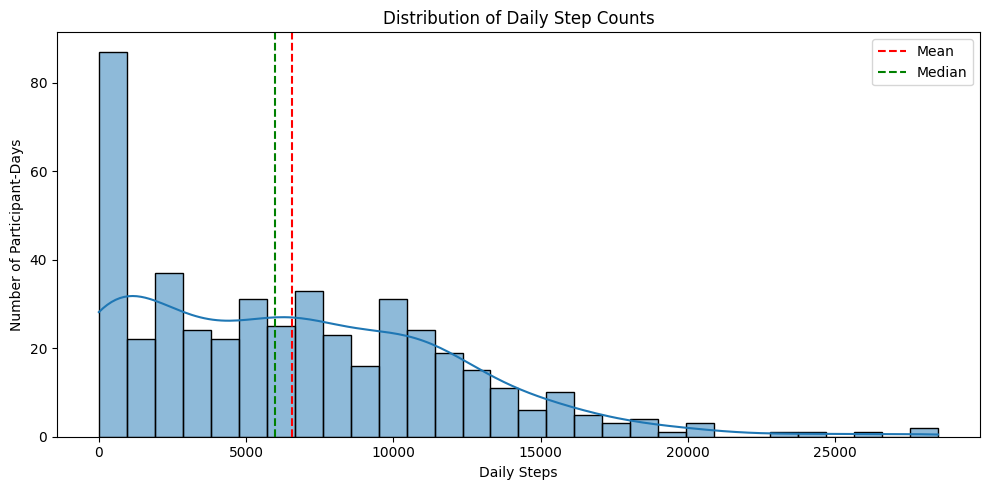

In [17]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=daily_activity,
    x='total_steps',
    bins=30,
    kde=True
)

plt.axvline(
    daily_activity['total_steps'].mean(),
    color='red',
    linestyle='--',
    label='Mean'
)

plt.axvline(
    daily_activity['total_steps'].median(),
    color='green',
    linestyle='--',
    label='Median'
)

plt.title('Distribution of Daily Step Counts')
plt.xlabel('Daily Steps')
plt.ylabel('Number of Participant-Days')
plt.legend()
plt.tight_layout()
plt.show()

The histogram reveals a positively skewed distribution of daily step counts, with a substantial concentration of low-activity observations and a relatively long right tail. The mean exceeds the median, indicating that a smaller number of highly active days influence the overall average. This confirms that daily activity levels vary considerably across participant-days.

In [18]:
## Compare complete and incomplete days

In [19]:
# Compare daily steps between complete and incomplete days

completeness_comparison = daily_activity.groupby(
    'is_complete_day'
).agg(
    recorded_days=('total_steps', 'count'),
    mean_steps=('total_steps', 'mean'),
    median_steps=('total_steps', 'median'),
    std_steps=('total_steps', 'std'),
    zero_step_days=('total_steps', lambda x: (x == 0).sum())
).reset_index()

completeness_comparison['day_type'] = (
    completeness_comparison['is_complete_day']
    .map({True: 'Complete', False: 'Incomplete'})
)

completeness_comparison = completeness_comparison[
    ['day_type', 'recorded_days', 'mean_steps',
     'median_steps', 'std_steps', 'zero_step_days']
]

display(completeness_comparison.round(2))

,day_type,recorded_days,mean_steps,median_steps,std_steps,zero_step_days
0,Incomplete,224,7289.92,7231.5,4573.22,6
1,Complete,233,5831.92,4706.0,6011.08,55


A comparison of complete and incomplete participant-days revealed that incomplete days had a higher mean step count (7,289.92) than complete days (5,831.92). However, complete days exhibited greater variability and contained considerably more zero-step observations (55 versus 6). These findings demonstrate that recording completeness does not necessarily correspond to physical activity level. Therefore, completeness should be considered separately from activity measurements when interpreting daily behaviour

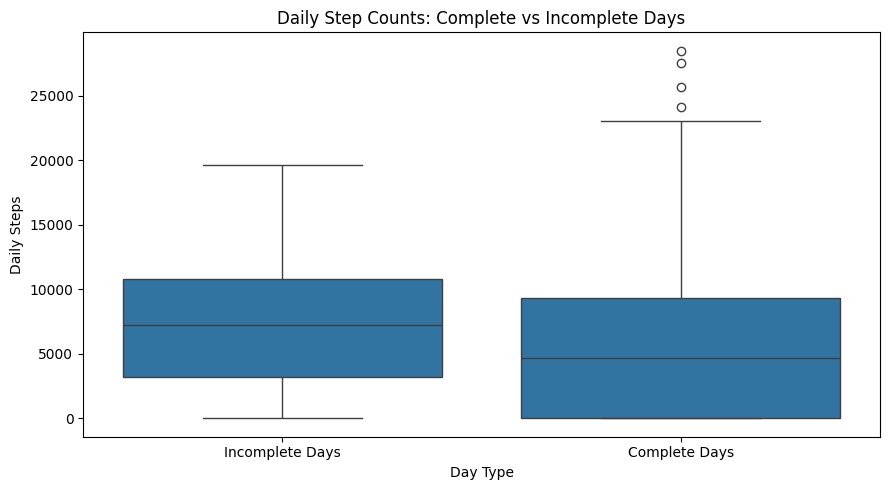

In [20]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=daily_activity,
    x='is_complete_day',
    y='total_steps'
)

plt.xticks(
    [0, 1],
    ['Incomplete Days', 'Complete Days']
)

plt.title('Daily Step Counts: Complete vs Incomplete Days')
plt.xlabel('Day Type')
plt.ylabel('Daily Steps')

plt.tight_layout()
plt.show()

The boxplot shows that incomplete days have a higher median step count than complete days, while complete days exhibit a wider distribution and several high-value observations. The lower quartile of complete days is zero, consistent with the high frequency of zero-step records in this group. These differences indicate substantial variation in daily activity and reinforce the need to distinguish tracker completeness from physical activity levels.

In [21]:
## Daily activity trends over the observation period

In [22]:
# Calculate daily average activity across participants

daily_step_trend = daily_activity.groupby(
    'activity_date'
).agg(
    avg_steps=('total_steps', 'mean'),
    median_steps=('total_steps', 'median'),
    participant_count=('id', 'nunique')
).reset_index()

daily_step_trend = daily_step_trend.sort_values('activity_date')

display(daily_step_trend.round(2))

,activity_date,avg_steps,median_steps,participant_count
0,2016-03-12,2771.50,2771.5,2
1,2016-03-13,1613.00,1613.0,2
2,2016-03-14,5728.00,5728.0,2
3,2016-03-15,2953.00,2953.0,2
4,2016-03-16,7311.00,7311.0,2
5,2016-03-17,4470.00,4470.0,2
6,2016-03-18,658.50,658.5,2
7,2016-03-19,2851.00,2851.0,2
8,2016-03-20,5187.00,5187.0,2
9,2016-03-21,5719.00,5719.0,2


Daily average step counts varied throughout the observation period. However, participant coverage was highly uneven, increasing from only two participants during the initial dates to 35 participants by April 2. Coverage subsequently declined towards the end of the study period. Consequently, date-wise averages are influenced by changes in participant composition and should not be interpreted as a uniform population-level activity trend.

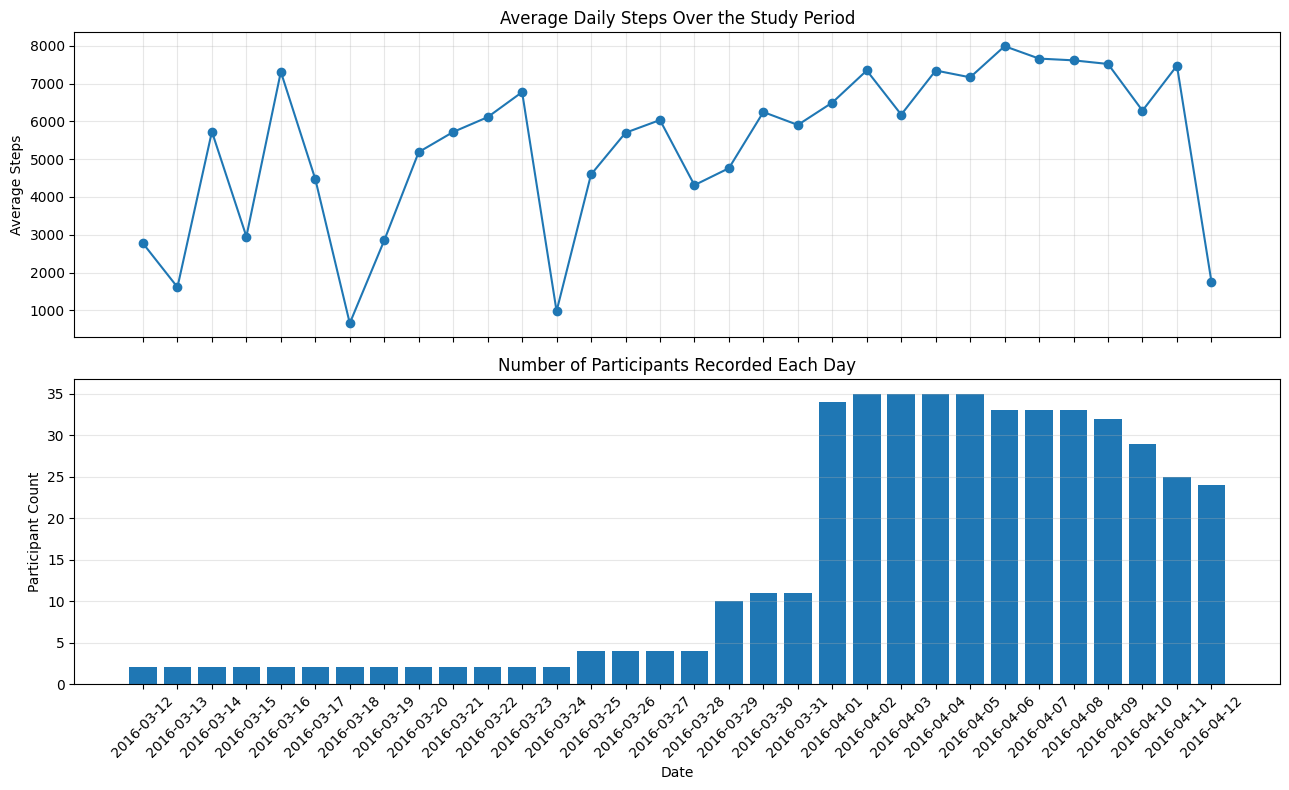

In [23]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 8),
    sharex=True
)

# Plot 1: Average daily steps
axes[0].plot(
    daily_step_trend['activity_date'],
    daily_step_trend['avg_steps'],
    marker='o'
)

axes[0].set_title('Average Daily Steps Over the Study Period')
axes[0].set_ylabel('Average Steps')
axes[0].grid(alpha=0.3)

# Plot 2: Participant coverage
axes[1].bar(
    daily_step_trend['activity_date'],
    daily_step_trend['participant_count']
)

axes[1].set_title('Number of Participants Recorded Each Day')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Participant Count')
axes[1].grid(axis='y', alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The daily activity trend exhibited considerable fluctuations, with average step counts generally higher during early April than during the initial observation period. However, participant coverage increased substantially from two participants per day in mid-March to approximately 35 participants per day in early April, before declining towards the end of the study. Consequently, changes in daily averages may reflect differences in participant composition and coverage rather than genuine temporal changes in activity. These trends should therefore be interpreted cautiously

In [24]:
## Weekday vs weekend activity

In [27]:
# Create weekday/weekend classification
daily_activity_clean = pd.read_csv(
    DATA_DIR / 'daily_activity_clean.csv',
    parse_dates=['activity_date']
)

daily_activity_clean['day_of_week'] = (
    daily_activity_clean['activity_date'].dt.day_name()
)

daily_activity_clean['day_type'] = (
    daily_activity_clean['activity_date']
    .dt.dayofweek
    .map(lambda day: 'Weekend' if day >= 5 else 'Weekday')
)

# Compare activity between weekdays and weekends

weekday_comparison = daily_activity_clean.groupby(
    'day_type'
).agg(
    recorded_days=('total_steps', 'count'),
    participant_count=('id', 'nunique'),
    mean_steps=('total_steps', 'mean'),
    median_steps=('total_steps', 'median'),
    std_steps=('total_steps', 'std')
).reset_index()

display(weekday_comparison.round(2))

,day_type,recorded_days,participant_count,mean_steps,median_steps,std_steps
0,Weekday,310,35,6528.61,6525.0,5132.06
1,Weekend,147,35,6584.42,5290.0,5939.64


The comparison of weekday and weekend activity showed similar mean step counts, with 6,528.61 steps on weekdays and 6,584.42 steps on weekends. However, weekend observations had a lower median (5,290 versus 6,525) and higher variability. This suggests that weekend activity patterns may be more dispersed, with differences between the mean and median indicating the influence of high-activity observations. These findings are descriptive and do not establish a statistically significant weekday–weekend difference.

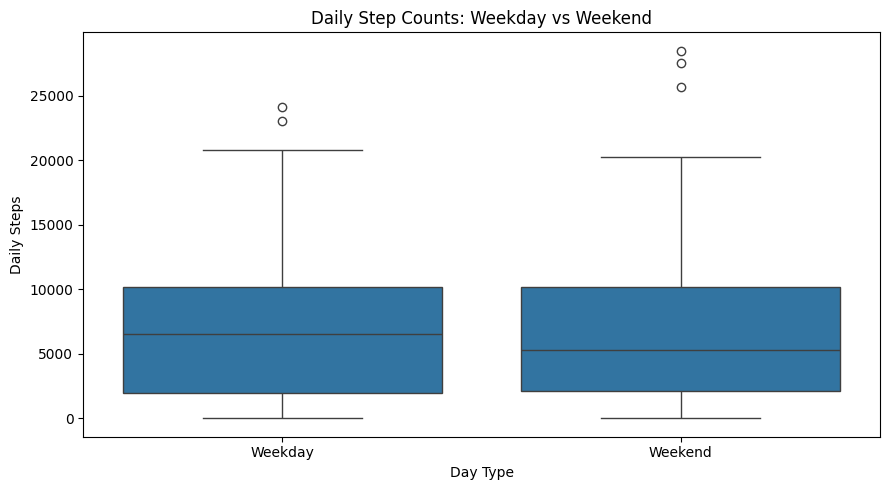

In [28]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=daily_activity_clean,
    x='day_type',
    y='total_steps',
    order=['Weekday', 'Weekend']
)

plt.title('Daily Step Counts: Weekday vs Weekend')
plt.xlabel('Day Type')
plt.ylabel('Daily Steps')

plt.tight_layout()
plt.show()

In [29]:
## Participant-level weekday vs weekend comparison

In [30]:
# Calculate each participant's average steps by day type

participant_weekday_comparison = daily_activity_clean.groupby(
    ['id', 'day_type']
).agg(
    avg_steps=('total_steps', 'mean'),
    recorded_days=('total_steps', 'count')
).reset_index()

# Convert weekday and weekend averages into separate columns

participant_weekday_comparison = (
    participant_weekday_comparison.pivot(
        index='id',
        columns='day_type',
        values='avg_steps'
    )
    .reset_index()
)

# Calculate each participant's weekend-weekday difference

participant_weekday_comparison['weekend_minus_weekday'] = (
    participant_weekday_comparison['Weekend']
    - participant_weekday_comparison['Weekday']
)

display(participant_weekday_comparison.round(2))

day_type,id,Weekday,Weekend,weekend_minus_weekday
0,1503960366,11313.23,12349.67,1036.44
1,1624580081,5042.38,2458.00,-2584.38
2,1644430081,7405.00,12079.50,4674.50
3,1844505072,2993.00,4935.75,1942.75
4,1927972279,1585.25,3372.00,1786.75
5,2022484408,12900.75,10723.25,-2177.50
6,2026352035,3617.00,2944.25,-672.75
7,2320127002,3815.12,1785.00,-2030.12
8,2347167796,8899.82,12275.75,3375.93
9,2873212765,6299.00,7311.75,1012.75


The pooled comparison showed almost identical mean step counts for weekdays and weekends. The participant-level comparison explains why: individual patterns differ considerably, with nearly equal numbers of participants more active on either type of day.

This illustrates why pooled averages alone can hide individual behavioural differences.

One limitation: this table compares averages without showing how many weekday and weekend observations support each participant's averages. Participants with very few observations in either group may have less reliable estimates.

In [31]:
# Summarise within-participant weekday/weekend differences

difference_summary = (
    participant_weekday_comparison['weekend_minus_weekday']
    .describe()
)

print("Weekend - Weekday Difference Summary:")
display(difference_summary.to_frame(
    name='Step Difference'
).round(2))

# Count participants by direction of difference

differences = participant_weekday_comparison[
    'weekend_minus_weekday'
]

print("\nParticipant Comparison:")
print("More active on weekends:", (differences > 0).sum())
print("More active on weekdays:", (differences < 0).sum())
print("Equal average steps:", (differences == 0).sum())

# Identify largest differences in both directions

print("\nLargest Weekend Increases:")
display(
    participant_weekday_comparison.nlargest(
        5, 'weekend_minus_weekday'
    ).round(2)
)

print("\nLargest Weekday Increases:")
display(
    participant_weekday_comparison.nsmallest(
        5, 'weekend_minus_weekday'
    ).round(2)
)

Weekend - Weekday Difference Summary:


,Step Difference
count,35.00
mean,9.86
std,3202.29
min,-7040.25
25%,-1389.20
50%,0.00
75%,1752.96
max,6799.00



Participant Comparison:
More active on weekends: 17
More active on weekdays: 17
Equal average steps: 1

Largest Weekend Increases:


day_type,id,Weekday,Weekend,weekend_minus_weekday
34,8877689391,15150.75,21949.75,6799.00
19,4702921684,6506.36,11895.25,5388.89
2,1644430081,7405.00,12079.50,4674.50
21,5577150313,7090.00,11265.00,4175.00
8,2347167796,8899.82,12275.75,3375.93



Largest Weekday Increases:


day_type,id,Weekday,Weekend,weekend_minus_weekday
20,5553957443,10701.50,3661.25,-7040.25
25,6775888955,7742.00,1193.00,-6549.00
31,8378563200,10030.25,4345.25,-5685.00
28,7086361926,7913.00,2485.75,-5427.25
15,4319703577,8579.89,5542.67,-3037.22


Finding / Conclusion (report-ready)
Participant-level comparison revealed heterogeneous weekday–weekend activity patterns. Out of 35 participants, 17 recorded higher average step counts on weekends, 17 recorded higher averages on weekdays, and one had identical averages. The magnitude of individual differences varied considerably, with some participants showing substantially higher weekend activity and others showing substantially higher weekday activity. Thus, no consistent weekday–weekend preference was observed across the participants

In [32]:
## Analyse daily activity intensity and sedentary behaviour

In [33]:
# Descriptive statistics of daily activity duration

activity_duration_summary = daily_activity_clean[
    [
        'very_active_minutes',
        'fairly_active_minutes',
        'lightly_active_minutes',
        'sedentary_minutes'
    ]
].describe().T

display(activity_duration_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
very_active_minutes,457.0,16.62,28.92,0.0,0.0,0.0,25.0,202.0
fairly_active_minutes,457.0,13.07,36.21,0.0,0.0,1.0,16.0,660.0
lightly_active_minutes,457.0,170.07,122.21,0.0,64.0,181.0,257.0,720.0
sedentary_minutes,457.0,995.28,337.02,32.0,728.0,1057.0,1285.0,1440.0


Daily activity duration analysis revealed that sedentary behaviour accounted for the largest share of recorded time, averaging 995.28 minutes per participant-day. Light activity averaged 170.07 minutes, whereas very active and fairly active durations were considerably lower, at 16.62 and 13.07 minutes respectively. The median very-active duration was zero, indicating that at least half of the recorded participant-days contained no very-active minutes. These findings suggest that recorded daily behaviour was dominated by sedentary and light activity, although incomplete-day observations and substantial variability must be considered when interpreting the results.

In [34]:
## Compare activity duration across complete and incomplete days

In [35]:
# Compare activity durations by day completeness

duration_comparison = daily_activity_clean.groupby(
    'is_complete_day'
).agg(
    recorded_days=('id', 'count'),
    very_active=('very_active_minutes', 'mean'),
    fairly_active=('fairly_active_minutes', 'mean'),
    lightly_active=('lightly_active_minutes', 'mean'),
    sedentary=('sedentary_minutes', 'mean')
).reset_index()

duration_comparison['day_type'] = (
    duration_comparison['is_complete_day']
    .map({True: 'Complete', False: 'Incomplete'})
)

duration_comparison = duration_comparison[
    ['day_type', 'recorded_days', 'very_active',
     'fairly_active', 'lightly_active', 'sedentary']
]

display(duration_comparison.round(2))

,day_type,recorded_days,very_active,fairly_active,lightly_active,sedentary
0,Incomplete,224,18.93,14.54,196.37,710.41
1,Complete,233,14.40,11.66,144.79,1269.15


Incomplete days exhibited higher average durations of very, fairly, and lightly active behaviour, whereas complete days showed substantially higher sedentary duration. The four activity-duration categories summed to approximately 940 minutes on incomplete days and 1,440 minutes on complete days. This indicates that differences in recording duration strongly influence the absolute duration comparisons. Consequently, activity proportions should also be examined before drawing conclusions about differences in behavioural composition.

In [36]:
## Compare activity composition using percentages

In [37]:
# Calculate the percentage of recorded time in each activity category

activity_columns = [
    'very_active_minutes',
    'fairly_active_minutes',
    'lightly_active_minutes',
    'sedentary_minutes'
]

daily_activity_clean['total_activity_minutes'] = (
    daily_activity_clean[activity_columns].sum(axis=1)
)

# Calculate participant-day activity percentages

for col in activity_columns:
    daily_activity_clean[col.replace('_minutes', '_pct')] = (
        daily_activity_clean[col] /
        daily_activity_clean['total_activity_minutes'].replace(0, np.nan)
    ) * 100

# Compare average activity composition by completeness

activity_percentage_comparison = daily_activity_clean.groupby(
    'is_complete_day'
).agg(
    very_active_pct=('very_active_pct', 'mean'),
    fairly_active_pct=('fairly_active_pct', 'mean'),
    lightly_active_pct=('lightly_active_pct', 'mean'),
    sedentary_pct=('sedentary_pct', 'mean')
).reset_index()

activity_percentage_comparison['day_type'] = (
    activity_percentage_comparison['is_complete_day']
    .map({True: 'Complete', False: 'Incomplete'})
)

activity_percentage_comparison = activity_percentage_comparison[
    ['day_type', 'very_active_pct', 'fairly_active_pct',
     'lightly_active_pct', 'sedentary_pct']
]

display(activity_percentage_comparison.round(2))

,day_type,very_active_pct,fairly_active_pct,lightly_active_pct,sedentary_pct
0,Incomplete,2.05,1.51,20.50,75.93
1,Complete,1.00,0.81,10.05,88.14


Activity composition analysis revealed that complete days had a higher average sedentary proportion (88.14%) than incomplete days (75.93%). Conversely, incomplete days had higher proportions of very active, fairly active and lightly active behaviour. These results suggest that recording completeness is associated with differences in the observed composition of daily activity. However, the findings should be interpreted cautiously because tracker non-wear and participant-level differences may influence the comparison

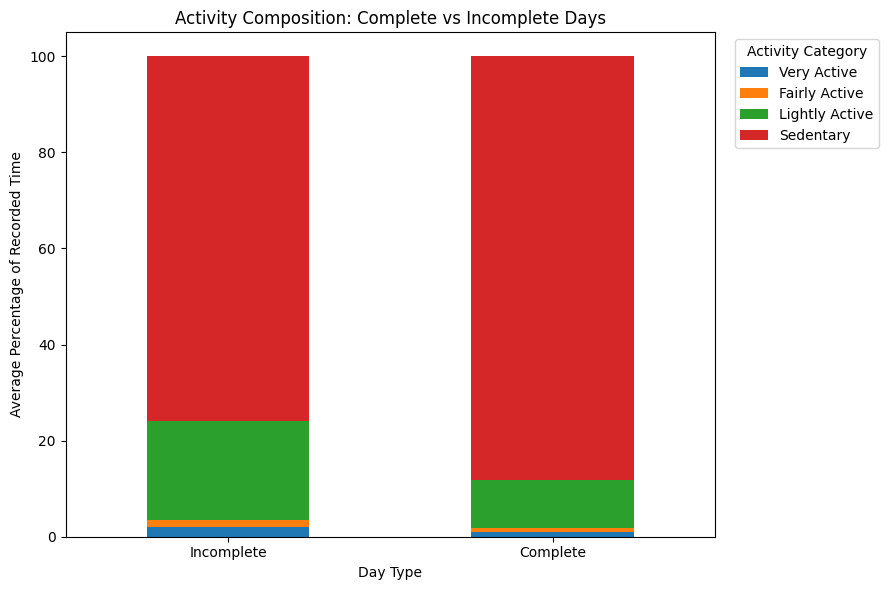

In [38]:
# Prepare data for visualisation

plot_data = activity_percentage_comparison.set_index(
    'day_type'
)[
    [
        'very_active_pct',
        'fairly_active_pct',
        'lightly_active_pct',
        'sedentary_pct'
    ]
]

plot_data.columns = [
    'Very Active',
    'Fairly Active',
    'Lightly Active',
    'Sedentary'
]

# Plot activity composition

plot_data.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 6)
)

plt.title('Activity Composition: Complete vs Incomplete Days')
plt.xlabel('Day Type')
plt.ylabel('Average Percentage of Recorded Time')
plt.xticks(rotation=0)
plt.legend(title='Activity Category', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

Finding:
The stacked bar chart illustrates that sedentary behaviour dominates recorded time in both complete and incomplete days. Complete days have a substantially higher sedentary proportion, whereas incomplete days have a greater contribution from all three active categories. The largest difference is observed in lightly active behaviour. These results reinforce the importance of considering tracker recording completeness when analysing daily activity composition.